# Практичне заняття 2. Частина 2 — операції над матрицями через обробку зображень

## Завдання 4. Напрямлені різниці та оператор Собеля

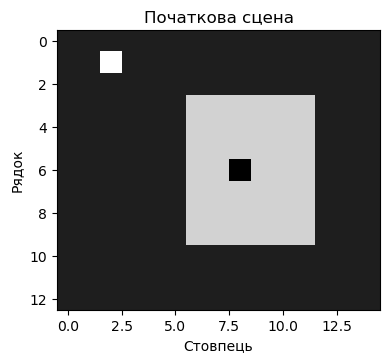

In [1]:
import numpy as np
import matplotlib.pyplot as plt

G = np.full((13, 15), 30, dtype=np.uint8)
G[3:10, 6:12] = 210
G[1, 2] = 255
G[6, 8] = 0

def local_filter(image, kernel, border="edge"):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)
    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Потрібні двовимірні матриці")
    kh, kw = kernel.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Розміри ядра мають бути непарними")
    if border not in ("edge", "constant"):
        raise ValueError("border: edge або constant")
    padded = np.pad(image, ((kh // 2, kh // 2), (kw // 2, kw // 2)),
                    mode=border)
    result = np.empty_like(image)
    for row in range(image.shape[0]):
        for col in range(image.shape[1]):
            patch = padded[row:row + kh, col:col + kw]
            result[row, col] = np.sum(patch * kernel)
    return result

def show_fields(image, gx, gy, magnitude, limit, label):
    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    specs = [
        (image, "Зображення", "gray", 0, 255),
        (gx, label + ": Gx", "coolwarm", -limit, limit),
        (gy, label + ": Gy", "coolwarm", -limit, limit),
        (magnitude, label + ": сила", "gray", 0, np.sqrt(2) * limit)
    ]
    for ax, (data, title, cmap, vmin, vmax) in zip(axes, specs):
        plot = ax.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax,
                         interpolation="nearest", origin="upper")
        ax.set_title(title)
        ax.set_xlabel("Стовпець")
        ax.set_ylabel("Рядок")
        fig.colorbar(plot, ax=ax, shrink=0.65)
    plt.tight_layout()
    plt.show()

def show_gray(items):
    fig, axes = plt.subplots(1, len(items), figsize=(4 * len(items), 4))
    for ax, (data, title) in zip(np.atleast_1d(axes), items):
        ax.imshow(data, cmap="gray", vmin=0, vmax=255,
                  interpolation="nearest", origin="upper")
        ax.set_title(title)
        ax.set_xlabel("Стовпець")
        ax.set_ylabel("Рядок")
    plt.tight_layout()
    plt.show()

controls = [(6, 5), (2, 9), (11, 13)]
show_gray([(G, "Початкова сцена")])

## А. Напрямлені різниці

### Ручні розрахунки для контрольних точок
1. **Координата (6, 5)** — ліва вертикальна межа прямокутника (зліва фон = 30, справа прямокутник = 210):
   * $G_x$ (правий мінус лівий сусід): $210 - 30 = +180$
   * $G_y$ (нижній мінус верхній сусід усередині однорідної вертикальної межі): $210 - 210 = 0$
2. **Координата (2, 9)** — верхня горизонтальна межа прямокутника (зверху фон = 30, знизу прямокутник = 210):
   * $G_x$ (всередині горизонтальної межі): $210 - 210 = 0$
   * $G_y$ (нижній мінус верхній сусід): $210 - 30 = +180$
3. **Координата (11, 13)** — однорідна фонова зона внизу зображення (значення навколо = 30):
   * $G_x = 30 - 30 = 0$
   * $G_y = 30 - 30 = 0$

### Таблиця А

| Контрольна координата | Прогноз Gx | Фактичне Gx | Прогноз Gy | Фактичне Gy | Сила |
| --- | ---: | ---: | ---: | ---: | ---: |
| (6,5) | +180 | 180.0 | 0 | 0.0 | 180.0 |
| (2,9) | 0 | 0.0 | +180 | 180.0 | 180.0 |
| (11,13) | 0 | 0.0 | 0 | 0.0 | 0.0 |

(6, 5) Gx = 180.0 Gy = 0.0 сила = 180.0
(2, 9) Gx = 0.0 Gy = 180.0 сила = 180.0
(11, 13) Gx = 0.0 Gy = 0.0 сила = 0.0


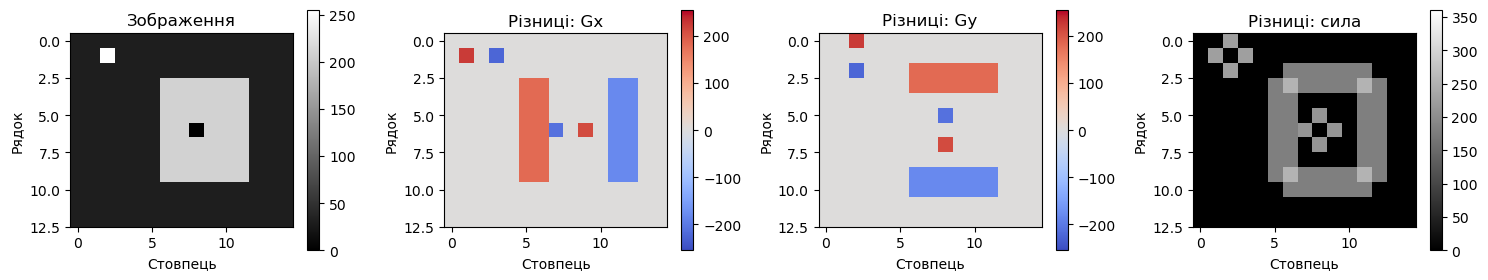

Зміна знаків ядер зберегла силу: True


In [2]:
kx = np.array([[-1, 0, 1]], dtype=np.float64)
ky = kx.T.copy()

gx = local_filter(G, kx)
gy = local_filter(G, ky)
magnitude = np.hypot(gx, gy)

for row, col in controls:
    print((row, col), "Gx =", gx[row, col], "Gy =", gy[row, col],
          "сила =", round(float(magnitude[row, col]), 2))

show_fields(G, gx, gy, magnitude, limit=255, label="Різниці")

gx_reversed = local_filter(G, -kx)
gy_reversed = local_filter(G, -ky)
print("Зміна знаків ядер зберегла силу:",
      np.allclose(magnitude, np.hypot(gx_reversed, gy_reversed)))

### Питання до частини А

- **Яка компонента сильніше реагує на вертикальні межі прямокутника, а яка — на горизонтальні? Не плутайте напрям зміни з орієнтацією самої межі.**
  Компонента $G_x$ (горизонтальна різниця) сильніше реагує на вертикальні межі, оскільки зміна інтенсивності відбувається при переході по горизонталі (зліва направо). Компонента $G_y$ (вертикальна різниця) сильніше реагує на горизонтальні межі, де інтенсивність змінюється вздовж вертикалі (згори вниз).
- **Что означає додатна й від'ємна відповідь? Чому різні боки прямокутника можуть мати протилежні знаки?**
  Додатна відповідь означає збільшення інтенсивності при переміщенні в напрямку осей (праворуч або вниз), а від'ємна — її зменшення. Протилежні боки прямокутника мають різні знаки, тому що на лівому/верхньому боці ми переходимо від темного фону до світлого прямокутника (+), а на правому/нижньому — від світлого прямокутника назад до темного фону (-).
- **Чому зміна знаків обох ядер не змінює силу? Чому заміна сили на Gx+Gy могла б втратити частину меж?**
  Зміна знаків ядер міняє знаки компонент $G_x$ та $G_y$ на протилежні, але під час обчислення сили градієнта використовується квадрат або модуль ($\sqrt{G_x^2 + G_y^2}$), тому піднесення до квадрата нівелює знак. Заміна евклідової норми (сили) на просту суму $G_x + G_y$ призвела б до взаємного знищення додатних і від'ємних значень у певних напрямках (скасування сигналів), що спричинило б втрату частини важливих меж.

## Б. Оператор Собеля

### Ручні розрахунки для Собеля в точці (6,5)
В околі $3 \times 3$ навколо (6,5) зліва знаходиться фон (30), справа — прямокутник (210). Перепад інтенсивності дорівнює $210 - 30 = 180$.
Ядро `sobel_x` містить стовпці `[-1, 0, 1]` зі зважуванням рядків `[1, 2, 1]`.
Сума коефіцієнтів першого стовпця = $-1 - 2 - 1 = -4$, третього = $+1 + 2 + 1 = +4$.
* $S_x = (-4 \cdot 30) + (4 \cdot 210) = -120 + 840 = 720$
* $S_y$ (зміна уздовж вертикалі на однорідній вертикальній межі дорівнює нулю) $= 0$
* Сила Собеля: $\sqrt{720^2 + 0^2} = 720$

### Таблиця Б

| Поріг | Вхід | Прогноз збережених меж | Кількість позначених пікселів | Що сталося біля окремих точок |
| ---: | :--- | :--- | ---: | :--- |
| 120 | Початкова G | Зберегнуться всі межі та контури (весь периметр) | 68 | Окремі точки створюють дуже сильні локальні піки, вони чітко позначені. |
| 400 | Початкова G | Збережуться лише основні чіткі межі прямокутника | 36 | Точки також дають достатньо сильний відгук і залишаються позначеними. |
| 700 | Початкова G | Тільки найсильніші перепади (кути та частини країв) | 16 | Окремі точки можуть зникати або давати меншу кількість пікселів через високий поріг. |
| 400 | Після усереднення 3×3 | Межі стануть тоншими або дещо ослабленими через згладжування | 36 | Окремі точки значно розмиваються і повністю зникають нижче порогу 400. |

Окіл (6,5):
 [[ 30  30 210]
 [ 30  30 210]
 [ 30  30 210]]
Суми коефіцієнтів: 0.0 0.0
(6, 5) Sx = 720.0 Sy = 0.0 сила = 720.0
(2, 9) Sx = 0.0 Sy = 720.0 сила = 720.0
(11, 13) Sx = 0.0 Sy = 0.0 сила = 0.0
Максимальна сила: 763.6753236814714
Позначених пікселів: 56
Форма й тип сили: (13, 15) float64


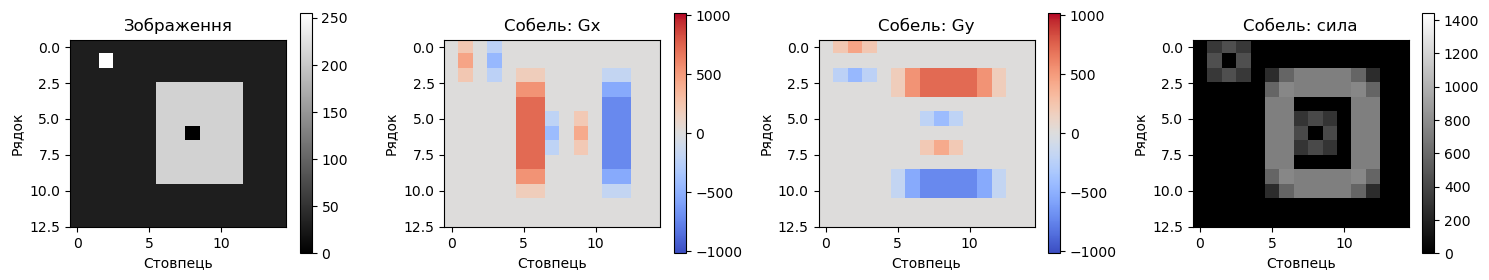

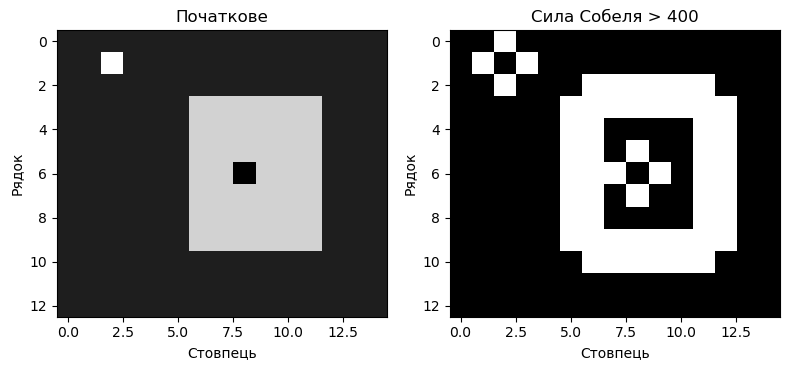

Позначок до розмиття: 56
Позначок після розмиття: 39
Максимальна сила до: 763.6753236814714 після: 480.00000000000006


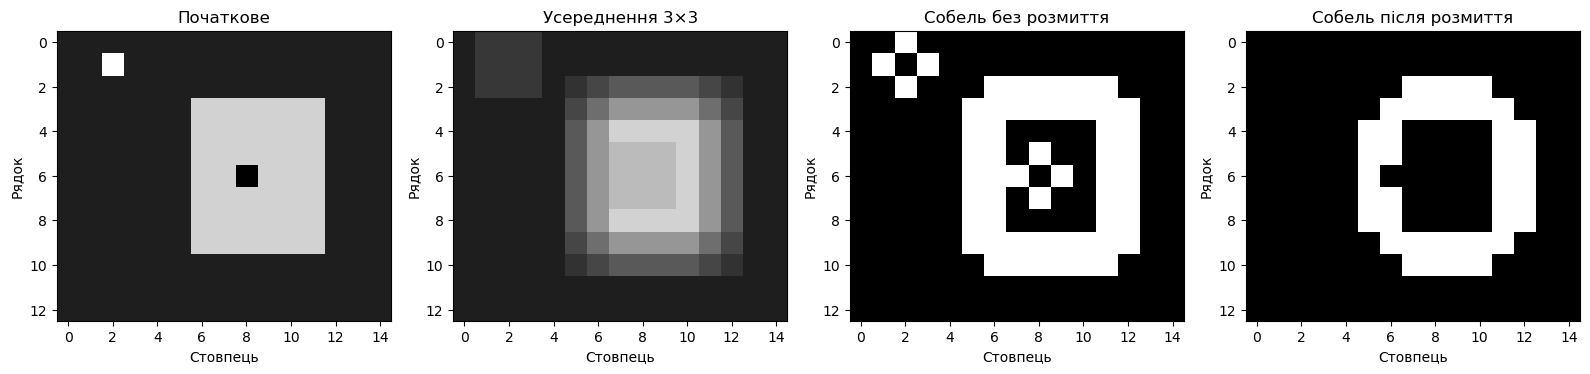

In [3]:
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)
sobel_y = sobel_x.T.copy()

sx = local_filter(G, sobel_x)
sy = local_filter(G, sobel_y)
sobel_magnitude = np.hypot(sx, sy)

threshold = 400  # Дослідіть 120, 400, 700
edge_mask = np.where(sobel_magnitude > threshold, 255, 0).astype(np.uint8)

print("Окіл (6,5):\n", G[5:8, 4:7])
print("Суми коефіцієнтів:", sobel_x.sum(), sobel_y.sum())
for row, col in controls:
    print((row, col), "Sx =", sx[row, col], "Sy =", sy[row, col],
          "сила =", round(float(sobel_magnitude[row, col]), 2))
print("Максимальна сила:", sobel_magnitude.max())
print("Позначених пікселів:", np.count_nonzero(edge_mask))
print("Форма й тип сили:", sobel_magnitude.shape, sobel_magnitude.dtype)

show_fields(G, sx, sy, sobel_magnitude, limit=4 * 255, label="Собель")
show_gray([(G, "Початкове"),
           (edge_mask, f"Сила Собеля > {threshold}")])

# Попереднє розмиття
blurred = local_filter(G, np.ones((3, 3)) / 9)

bsx = local_filter(blurred, sobel_x)
bsy = local_filter(blurred, sobel_y)
blurred_magnitude = np.hypot(bsx, bsy)

comparison_threshold = 400
mask_original = np.where(sobel_magnitude > comparison_threshold,
                         255, 0).astype(np.uint8)
mask_blurred = np.where(blurred_magnitude > comparison_threshold,
                        255, 0).astype(np.uint8)

print("Позначок до розмиття:", np.count_nonzero(mask_original))
print("Позначок після розмиття:", np.count_nonzero(mask_blurred))
print("Максимальна сила до:", sobel_magnitude.max(),
      "після:", blurred_magnitude.max())

show_gray([
    (G, "Початкове"), (blurred, "Усереднення 3×3"),
    (mask_original, "Собель без розмиття"),
    (mask_blurred, "Собель після розмиття")
])

### Питання до частини Б та Висновки

- **Чому сума коефіцієнтів кожного ядра дорівнює нулю? Що це означає для рівномірної ділянки?**
  Сума коефіцієнтів ядер Собеля дорівнює нулю, оскільки оператор призначений для пошуку змін (градієнта), а не для збереження яскравості. Для абсолютно рівномірної ділянки (де всі сусідні пікселі мають однакову інтенсивність) множення на такі ядра завжди дає нульовий результат, що повністю пригнічує фон.
- **Чому сила Собеля може перевищувати 255? Чому її не можна одразу записати в uint8?**
  Через те, що ядра Собеля мають ваги на зразок `1, 2, 1` та підсумовують добутки по всьому вікну $3 \times 3$, максимальне теоретичне значення сили може значно перевищувати 255 (наприклад, досягати понад 1000 для різких перепадів). Формат `uint8` обмежений діапазоном 0–255, тому пряме збереження призвело б до переповнення та спотворення даних (кліпінгу). Саме тому обчислення виконуються у `float64`, а порогова фільтрація застосовується до повного діапазону.
- **Що дає і що забирає попереднє розмиття? Чи є менша кількість позначених пікселів достатнім доказом кращого результату?**
  Попереднє розмиття діє як фільтр низьких частот: воно ефективно пригнічує дрібний шум та окремі поодинокі точки (шумові викиди), але водночас згладжує й розмиває справжні межі об'єктів, знижуючи максимальне значення градієнта. Меньша кількість позначених пікселів сама по собі **не є** доказом «кращого» результату, оскільки разом із шумом вона може знищувати корисні деталі та ковзати повз реальні контури.

### Загальний висновок
У ході лабораторної роботи було досліджено застосування напрямлених різниц та оператора Собеля для виділення меж на зображеннях. Завдяки комбінації просторового диференціювання та локального зважування сусідів оператор Собеля дозволяє ефективно знаходити контури об'єктів і визначати силу та напрям градієнта. Доведено, що попереднє розмиття зменшує чутливість до точкових шумів, проте призводить до розмиття меж, що вимагає ретельного підбору порогових значень залежно від поставленої задачі.